设三维学生 $t$ 分布随机变量 $\mathbf{X}'=(X_1,X_2,X_3)$，其定义为

$$
\mathbf{X}=\frac{\mathbf{Z}}{\sqrt{V/v}},
$$

其中 $\mathbf{Z}$ 是三维标准正态随机向量，三个分量相互独立，$V\sim \chi^2(v)$ 且与 $\mathbf{Z}$ 相互独立。

针对自由度 $v=5,10,20$，模拟产生该分布的随机数，并基于模拟结果估计 $X_1+X_2+X_3$ 的 $VaR_{0.95}$ 与 $ES_{0.95}$，分析参数 $v$ 的影响。

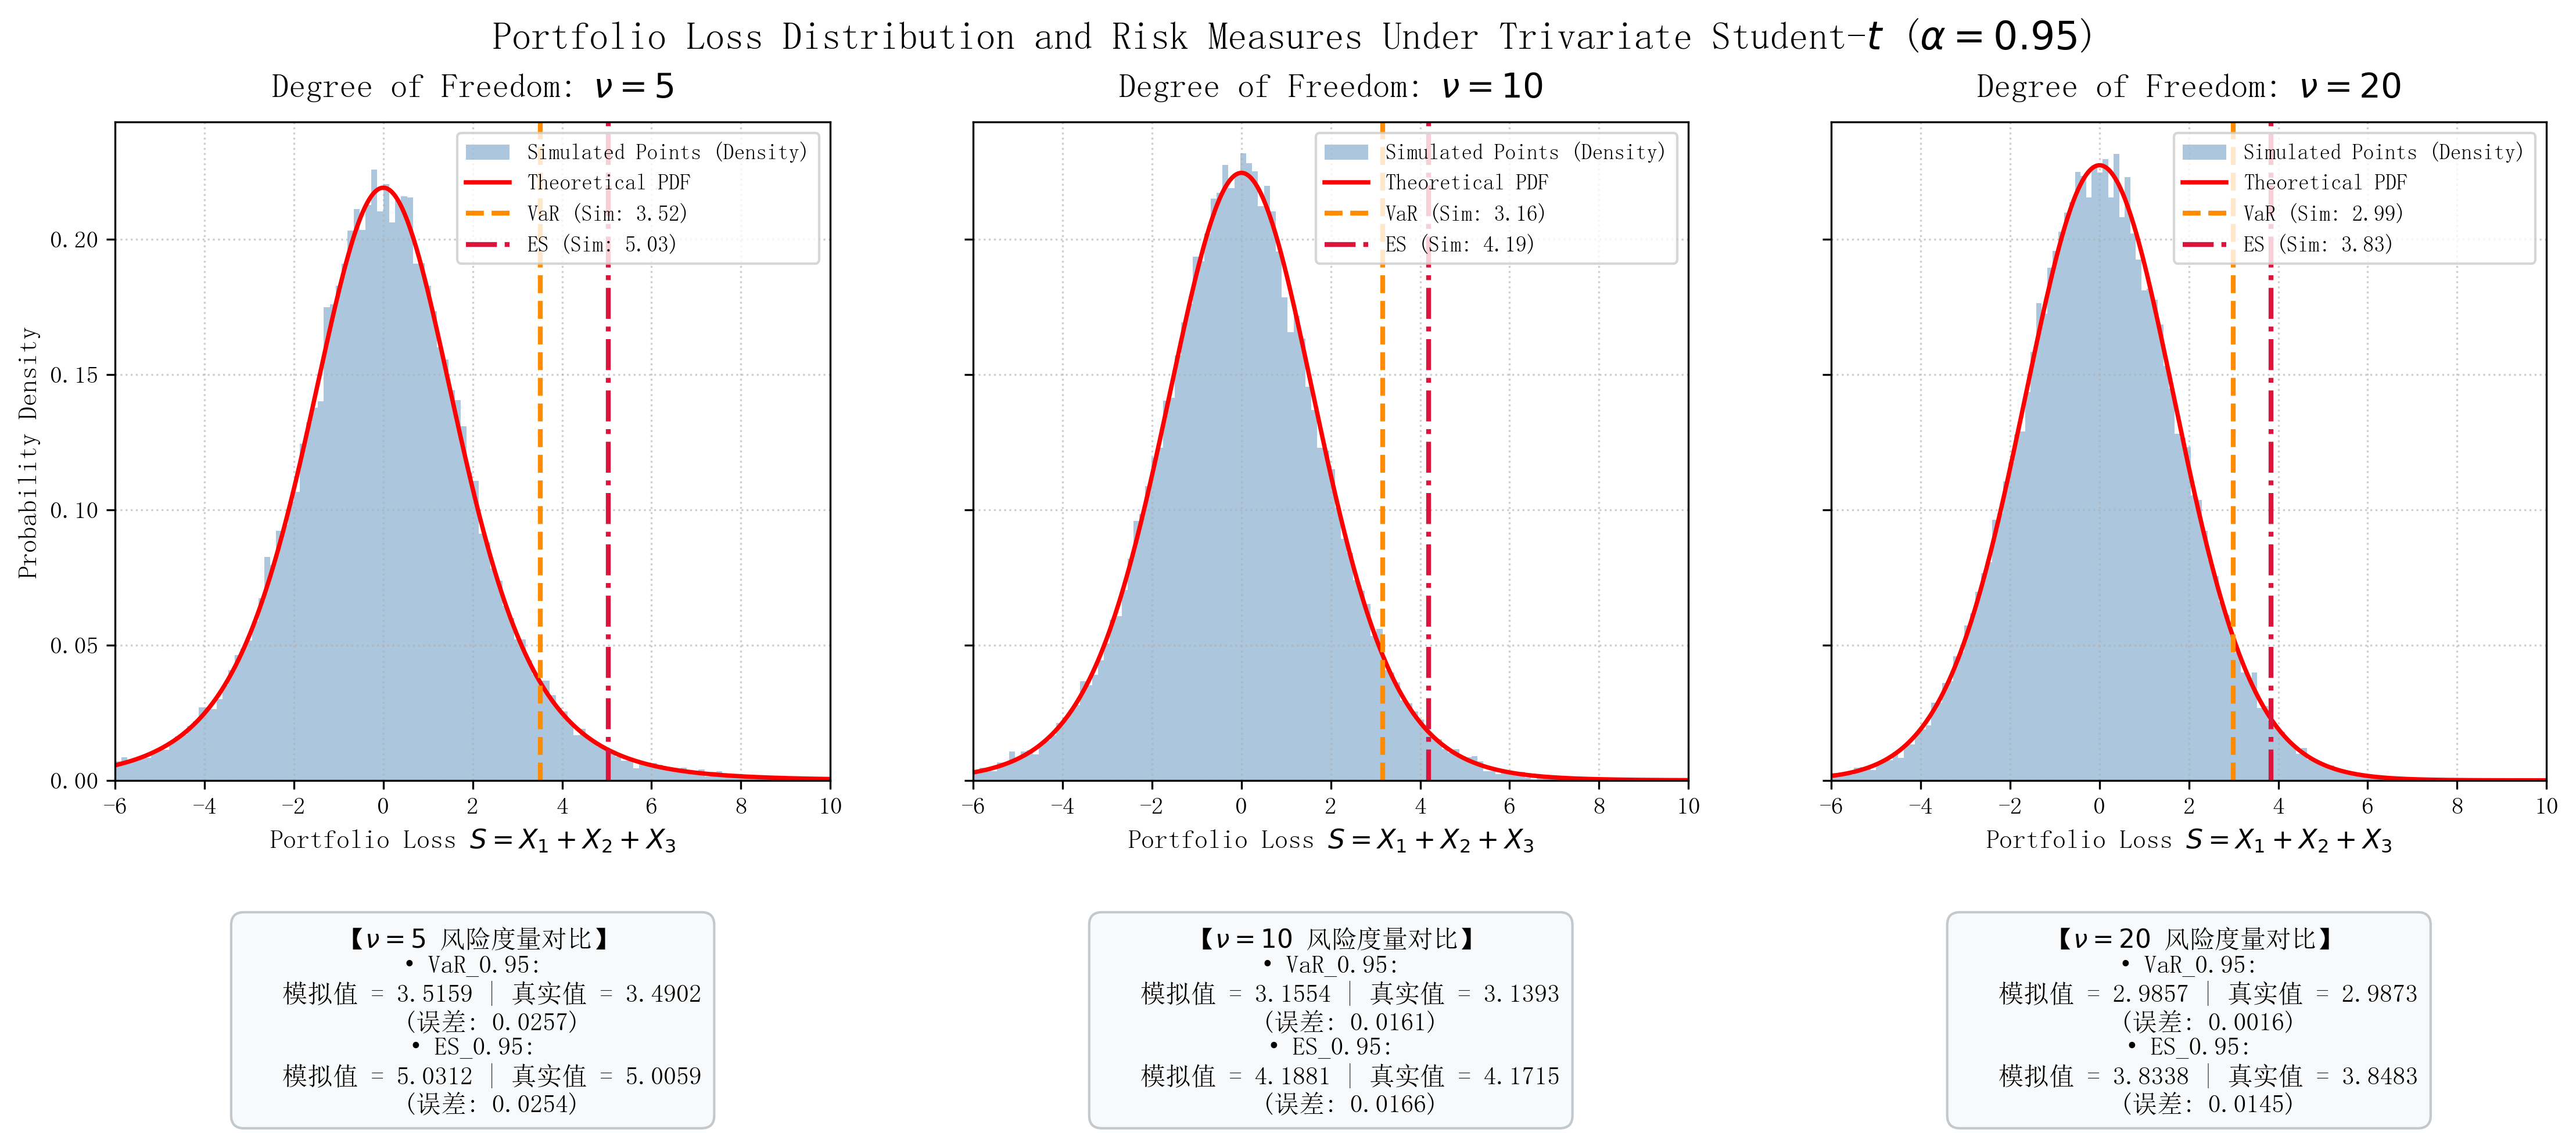

 nu  var_sim  var_theo   es_sim  es_theo
  5 3.515911  3.490166 5.031249 5.005850
 10 3.155366  3.139275 4.188060 4.171473
 20 2.985672  2.987300 3.833821 3.848314


In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

plt.rcParams['font.sans-serif'] = ['Simsun']  # 设置中文字体
plt.rcParams['axes.unicode_minus'] = False  # 解决负号显示问题
plt.rcParams['figure.dpi'] = 300  # 设置图片分辨率


# -------------------------------------------------------------
# 1. 模拟参数设定与随机数生成
# -------------------------------------------------------------
np.random.seed(42)  # 保证实验结果可复现

nu_list = [5, 10, 20]
alpha = 0.95
M = 50_000  # 模拟 5 万个样本（兼顾高精度与绘图流畅度）

# 创建 1x3 画布
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
plt.subplots_adjust(bottom=0.25)  # 底部留出空间标注指标数值

results = []

for idx, nu in enumerate(nu_list):
    ax = axes[idx]

    # (1) 抽取 3 维独立标准正态与卡方随机变量
    Z = np.random.standard_normal((M, 3))
    W = np.random.chisquare(df=nu, size=M)

    # (2) 构造 3 维学生 t 向量并计算组合和 S = X1 + X2 + X3
    scale = np.sqrt(W / nu)[:, np.newaxis]
    X = Z / scale
    S = np.sum(X, axis=1)

    # (3) 蒙特卡洛经验分位数估计
    var_sim = np.percentile(S, alpha * 100)
    es_sim = S[S > var_sim].mean()

    # (4) 理论真实值计算
    # S = sqrt(3) * T, T ~ t(nu)
    t_q = stats.t.ppf(alpha, df=nu)
    var_theo = np.sqrt(3) * t_q

    # 理论 ES 解析式
    t_pdf = stats.t.pdf(t_q, df=nu)
    es_theo_standard_t = (t_pdf / (1 - alpha)) * ((nu + t_q**2) / (nu - 1))
    es_theo = np.sqrt(3) * es_theo_standard_t

    results.append(
        {
            "nu": nu,
            "var_sim": var_sim,
            "var_theo": var_theo,
            "es_sim": es_sim,
            "es_theo": es_theo,
        }
    )

    # (5) 绘制模拟数据的经验直方图 (截取展示区间 [-6, 10])
    plot_mask = (S >= -6) & (S <= 10)
    ax.hist(
        S[plot_mask],
        bins=120,
        density=True,
        alpha=0.45,
        color="steelblue",
        edgecolor="none",
        label="Simulated Points (Density)",
    )

    # (6) 叠加理论概率密度曲线 (PDF)
    x_grid = np.linspace(-6, 10, 500)
    # S 服从 scale 为 sqrt(3) 的学生 t 分布
    theo_pdf = stats.t.pdf(x_grid / np.sqrt(3), df=nu) / np.sqrt(3)
    ax.plot(x_grid, theo_pdf, "r-", lw=1.8, label="Theoretical PDF")

    # (7) 绘制 VaR 和 ES 标记线
    ax.axvline(
        var_sim,
        color="darkorange",
        linestyle="--",
        lw=2,
        label=f"VaR (Sim: {var_sim:.2f})",
    )
    ax.axvline(
        es_sim,
        color="crimson",
        linestyle="-.",
        lw=2,
        label=f"ES (Sim: {es_sim:.2f})",
    )

    # (8) 子图基本设置
    ax.set_title(rf"Degree of Freedom: $\nu = {nu}$", fontsize=14, pad=10)
    ax.set_xlabel(r"Portfolio Loss $S = X_1 + X_2 + X_3$", fontsize=11)
    if idx == 0:
        ax.set_ylabel("Probability Density", fontsize=11)
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="upper right", fontsize=9)
    ax.set_xlim([-6, 10])

    # (9) 在每个子图下方标注具体的模拟与真实值 (指标对比卡)
    annotation_text = (
        f"【$\\nu = {nu}$ 风险度量对比】\n"
        f"• VaR_0.95:\n"
        f"   模拟值 = {var_sim:.4f} | 真实值 = {var_theo:.4f}\n"
        f"   (误差: {abs(var_sim - var_theo):.4f})\n"
        f"• ES_0.95:\n"
        f"   模拟值 = {es_sim:.4f} | 真实值 = {es_theo:.4f}\n"
        f"   (误差: {abs(es_sim - es_theo):.4f})"
    )

    # 使用 figure transform 放置在各自子图的正下方
    ax.text(
        0.5,
        -0.22,
        annotation_text,
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=10.5,
        bbox=dict(
            boxstyle="round,pad=0.5",
            facecolor="#F7F9FA",
            edgecolor="#BDC3C7",
            alpha=0.9,
        ),
    )

plt.suptitle(
    r"Portfolio Loss Distribution and Risk Measures Under Trivariate Student-$t$ ($\alpha = 0.95$)",
    fontsize=16,
    y=0.98,
)
plt.show()

# 控制台打印整洁表格
df_report = pd.DataFrame(results)
print("=" * 60)
print(df_report.to_string(index=False))
print("=" * 60)